## Setup
Environment, imports, configuration prints.

In [1]:
import sys, subprocess
import os

In [2]:
import sys, os
print(sys.executable)      
print(sys.prefix)          
print(sys.version)
print(os.environ.get("VIRTUAL_ENV"), os.environ.get("CONDA_DEFAULT_ENV"))

/home/aa8624/thesis_2500/venv/bin/python
/home/aa8624/thesis_2500/venv
3.12.3 (main, Mar 23 2026, 19:04:32) [GCC 13.3.0]
None None


In [3]:
# List the key package versions in this environment 
print("python:", sys.executable)
print(subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
      .split("\n")[0:0] or "")
out = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
print("\n".join(l for l in out.splitlines() if l.lower().split()[0:1] and l.lower().split()[0] in
      ("torch", "torchvision", "torchaudio", "transformers", "huggingface-hub", "open_clip_torch", "open-clip-torch")))

python: /home/aa8624/thesis_2500/venv/bin/python

open_clip_torch           3.3.0
torch                     2.11.0+cu128
torchvision               0.26.0+cu128
transformers              5.13.0


In [4]:
#Pick the GPU (index from nvidia-smi)
os.environ["CUDA_VISIBLE_DEVICES"] = "3"   

In [5]:
# Imports and config printout. 
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))         
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import size_config as sc
import config
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler

%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)


print("PROJECT_ROOT :", config.PROJECT_ROOT)
print("QUICK_RUN    :", config.QUICK_RUN, "  (True = tiny settings, NOT for final results)")
print("family set   :", config.ACTIVE_FAMILY_SET, "| models:", config.MODELS_TO_RUN)
print("seeds        :", config.EXPERIMENT_SEEDS)
try:
    import torch; print("torch        :", torch.__version__, "| CUDA:", torch.cuda.is_available())
except ImportError:
    print("torch not installed (only the logistic-regression models will work)")

PROJECT_ROOT : /data/aa8624/thesis_2500
QUICK_RUN    : False   (True = tiny settings, NOT for final results)
family set   : diffusion_split | models: ['spectral_lr', 'handcrafted_lr', 'lbp_lr', 'cnn_densenet', 'supcon', 'npr', 'clip_frozen', 'biomedclip_frozen', 'rad_dino', 'dinov2_frozen']
seeds        : [42, 43, 44]
torch        : 2.11.0+cu128 | CUDA: True


In [6]:
# Number of data-loader workers for the CNN detectors
config.CNN_NUM_WORKERS = 4

**Optional installs (commented out on purpose).** These two lines change the Python environment, so they are not run
automatically. Uncomment and run them once if `import open_clip` or the Hugging Face hub version fails in Stage 5, then restart the kernel.

In [9]:
# One-off environment fixes. Execute only once.
!{sys.executable} -m pip uninstall -y huggingface-hub
!{sys.executable} -m pip install "huggingface-hub>=1.5,<2.0"
%pip install open_clip_torch

Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)


Note: you may need to restart the kernel to use updated packages.


## Data preprocessing

### Stage 2(A) — Organise dataset (inventory)
Scans all eight groups (real, three IP edit types, CycleGAN, three diffusion variants), **ignores mask files**, and gives every image the split of its real source, looked up by DICOM id in the real-pool manifest.

In [8]:
# Reload config, then the Stage 2 modules, so the latest files are used.
import importlib, sys, config

importlib.reload(config)
for name in list(sys.modules):
    if name.split(".")[-1] in {"build_inventory", "validate_dataset", "preprocess"}:
        importlib.reload(sys.modules[name])
        print("reloaded:", name)

ds = config.FORENSIC_CHARACTERISATION_DATASETS
print("file in use        :", config.__file__)
print("single real set    :", "REAL" in ds and "REAL_UNTOUCHED" not in ds and "REAL_SOURCE" not in ds)
print("paste sigma present:", hasattr(config, "diffusion_paste_sigma"))
print("groups             :", [v["frequency_group"] for v in ds.values()])

reloaded: stage2_dataset.validate_dataset
file in use        : /data/aa8624/thesis_2500/cxr_forensics/config.py
single real set    : True
paste sigma present: True
groups             : ['Real', 'IP_Blob', 'IP_CopyMove', 'IP_TextureTransplant', 'CycleGAN', 'Diffusion', 'Diffusion_EditOnly', 'Diffusion_Reconstruction']


In [9]:
# Build the master manifest of every group and summarise it
from stage2_dataset.build_inventory import build_master_manifest, summarise_manifest
master = build_master_manifest()
display(summarise_manifest(master))
master.head()

Scanning image families ...
  REAL                      2500 images
  IP_BLOB                   2500 images
  IP_COPY_MOVE              2500 images
  IP_TEXTURE_TRANSPLANT     2500 images
  CYCLEGAN                  2500 images
  DIFFUSION                 2491 images
  DIFFUSION_EDIT_ONLY       2491 images
  DIFFUSION_RECONSTRUCTION  2491 images
Saved master manifest (19973 images) -> /data/aa8624/thesis_2500/data/detection/manifests/dataset_master.csv


split,train,val,test,total
frequency_group,,,,
CycleGAN,1500,500,500,2500
Diffusion,1495,500,496,2491
Diffusion_EditOnly,1495,500,496,2491
Diffusion_Reconstruction,1495,500,496,2491
IP_Blob,1500,500,500,2500
IP_CopyMove,1500,500,500,2500
IP_TextureTransplant,1500,500,500,2500
Real,1500,500,500,2500


,image_id,dataset_key,group,frequency_group,generator,label,split,dicom_id,subject_id,study_id,source_disease_status,direction,folder_split,native_width,native_height,file_ext,file_size_bytes,filename,path
0,Real__p10060142_s50063022_8db0a014-69c5b1a5-56...,REAL,Real,Real,Real,0,test,8db0a014-69c5b1a5-5686d66f-a2a5bfa9-f720fe61,10060142,50063022,normal,NaN,test,2544,3056,.jpg,2413157,p10060142_s50063022_8db0a014-69c5b1a5-5686d66f...,/data/aa8624/thesis_2500/data/real/test/normal...
1,Real__p10060142_s52115374_7d5aa3f0-d3c4f9ce-fb...,REAL,Real,Real,Real,0,test,7d5aa3f0-d3c4f9ce-fba023b7-473879f7-169052b0,10060142,52115374,normal,NaN,test,2544,3056,.jpg,1770576,p10060142_s52115374_7d5aa3f0-d3c4f9ce-fba023b7...,/data/aa8624/thesis_2500/data/real/test/normal...
2,Real__p10060142_s52590350_32f259ea-97f841b2-02...,REAL,Real,Real,Real,0,test,32f259ea-97f841b2-02f4209d-6b8a0083-6e2f3c23,10060142,52590350,normal,NaN,test,3056,2544,.jpg,1835696,p10060142_s52590350_32f259ea-97f841b2-02f4209d...,/data/aa8624/thesis_2500/data/real/test/normal...
3,Real__p10060142_s54426084_37adf698-c7d3d5b5-4c...,REAL,Real,Real,Real,0,test,37adf698-c7d3d5b5-4ce945d5-7cc823fb-1a5921ed,10060142,54426084,normal,NaN,test,2544,3056,.jpg,1954978,p10060142_s54426084_37adf698-c7d3d5b5-4ce945d5...,/data/aa8624/thesis_2500/data/real/test/normal...
4,Real__p10060142_s59490715_817d3fbc-60f0a3ed-da...,REAL,Real,Real,Real,0,test,817d3fbc-60f0a3ed-da260a55-b3f2d4a1-368605a0,10060142,59490715,normal,NaN,test,2544,3056,.jpg,1901344,p10060142_s59490715_817d3fbc-60f0a3ed-da260a55...,/data/aa8624/thesis_2500/data/real/test/normal...


### Stage 2(B) — Validate dataset

In [11]:
from stage2_dataset.validate_dataset import validate_dataset
report = validate_dataset(master, strict=False)
print(report["ALL_HARD_CHECKS_PASSED"])

DATASET VALIDATION REPORT
images: 19973

[PASS] counts
        problems: {}
        unexpected_groups: []
[PASS] splits
        images_without_valid_split: 0
        folder_split_disagrees_with_source_split: 0
        examples: []
[PASS] patient_separation
        images_without_subject_id: 0
        n_patients_in_multiple_splits: 0
        patients_in_multiple_splits: []
[PASS] source_integrity
        synthetic_images_without_real_source: 0
        synthetic_images_with_a_different_split_than_their_source: 0
        examples: []
[FAIL] content_and_duplicates
        n_unreadable: 0
        unreadable: []
        n_mask_like: 0
        mask_like_images: []
        near_duplicate_pairs_total: 53232
        near_duplicate_pairs_within_same_split: 53012
        of_which_same_source_siblings: 52542
        near_duplicate_pairs_ACROSS_splits: 220
        cross_split_examples: [{'a': 'Real__p11324641_s54140478_2923c646-0c68bebd-cd5c359f-860ec3f2-80068420', 'b': 'Real__p11890992_s54592661_0d

distinct real-image pairs across splits: 8
of which same patient: 0


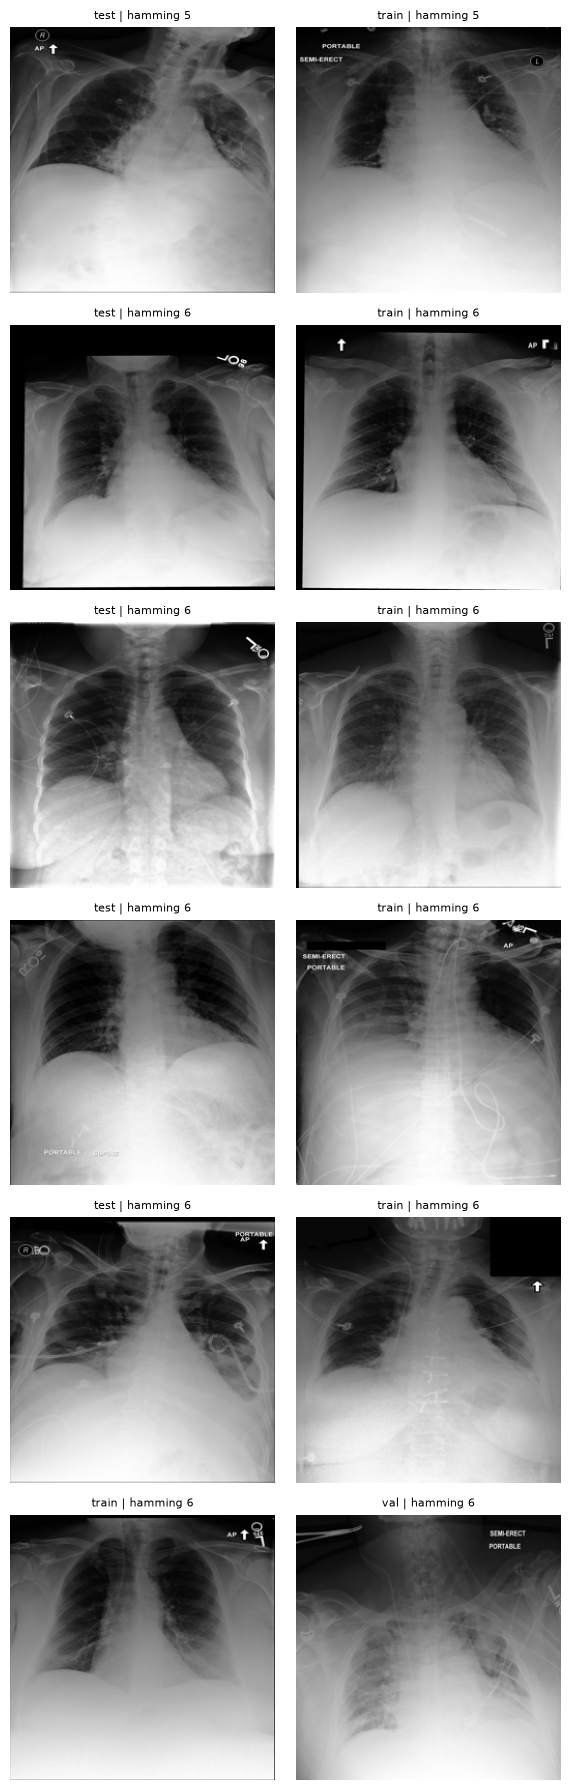

In [12]:
import numpy as np, matplotlib.pyplot as plt
from PIL import Image
import config
from stage2_dataset import validate_dataset as vd

real = master[master["group"] == config.REAL_GROUP].reset_index(drop=True)
H = np.stack([vd._average_hash(p, config.VALIDATION_NEAR_DUP_HASH_SIZE)[0] for p in real["path"]])
pairs = vd._near_duplicate_pairs(H, config.VALIDATION_NEAR_DUP_MAX_HAMMING)
cross = [(i, j, d) for i, j, d in pairs if real.split[i] != real.split[j]]
print("distinct real-image pairs across splits:", len(cross))
print("of which same patient:", sum(real.subject_id[i] == real.subject_id[j] for i, j, _ in cross))

show = sorted(cross, key=lambda t: t[2])[:6]
fig, ax = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)))
for r, (i, j, d) in enumerate(show):
    for c, k in enumerate((i, j)):
        ax[r, c].imshow(Image.open(real.path[k]).convert("L").resize((256, 256)), cmap="gray")
        ax[r, c].set_title(f"{real.split[k]} | hamming {d}", fontsize=8)
        ax[r, c].axis("off")
plt.tight_layout(); plt.show()

In [51]:
# import numpy as np, pandas as pd
# from PIL import Image
# import config
# from stage2_dataset import validate_dataset as vd

real = master[master.group == config.REAL_GROUP].drop_duplicates("dicom_id").reset_index(drop=True)
H = np.stack([vd._average_hash(p, config.VALIDATION_NEAR_DUP_HASH_SIZE)[0] for p in real.path])
pairs = vd._near_duplicate_pairs(H, config.VALIDATION_NEAR_DUP_MAX_HAMMING)
cross = [(i, j, d) for i, j, d in pairs if real.split[i] != real.split[j]]
print("real-only near-dup pairs:", len(pairs), "| across splits:", len(cross))

def small(p, n=64):
    return np.asarray(Image.open(p).convert("L").resize((n, n), Image.Resampling.BOX), dtype=np.float32).ravel()
rows = []
for i, j, d in cross:
    a, b = small(real.path[i]), small(real.path[j])
    rows.append(dict(a=real.image_id[i], b=real.image_id[j], hamming=d, corr=float(np.corrcoef(a, b)[0, 1]),
                     same_patient=real.subject_id[i] == real.subject_id[j]))
T = pd.DataFrame(rows).sort_values("corr", ascending=False)
print(T.head(10).round(3).to_string(index=False))
print("pairs with corr > 0.98:", int((T["corr"] > 0.98).sum()), "| same patient:", int(T["same_patient"].sum()))

real-only near-dup pairs: 18 | across splits: 8
                                                                     a                                                                      b  hamming  corr  same_patient
Real__p10043321_s59164130_24576d55-4cdc4874-729ddeaa-15966dc3-5ba0789b Real__p18916050_s57332197_9d2bf17a-d2fbd5d4-31cc0842-910fc10c-eef590d1        6 0.951         False
Real__p10240923_s55876778_5917911e-2d12b720-cc832384-bfa16b63-8d00dc62 Real__p12920877_s57511713_96b7a7e7-4d629d00-c583d548-53e99f75-f5d6bec5        6 0.943         False
Real__p19657904_s58397665_ccab8bcf-00f56156-f6458646-1d0b061b-344c1a4f Real__p18470025_s57116167_f13451af-d7719742-8d7fb7fd-43dd3145-5110ade0        6 0.935         False
Real__p11652443_s50735805_1423e2f6-4d55b9b8-1c84031a-aa0c0faf-b1c4783a Real__p10043321_s56415759_656fec15-3d665ecb-430c633f-f192f29d-481c6960        6 0.931         False
Real__p11888400_s51998648_f8ff0c0d-16c538cd-afb7bc14-bdd9f009-4a092128 Real__p18470025_s57116167_

In [52]:
cr = pd.DataFrame([(i, j, d) for i, j, d in cross], columns=["i", "j", "hamming"])
cr["test_img"] = [real.image_id[i] if real.split[i] == "test" else real.image_id[j] for i, j in zip(cr.i, cr.j)]
print("flagged real-image pairs across splits :", len(cr))
print("distinct real images involved          :", len(set(cr.i) | set(cr.j)), "of", len(real))
print("distinct patients involved             :", len(set(real.subject_id[list(set(cr.i) | set(cr.j))])))
print("pairs per split combination:\n", pd.Series([f"{real.split[i]}-{real.split[j]}" for i, j in zip(cr.i, cr.j)]).value_counts().to_string())
print("hamming distribution:\n", cr.hamming.value_counts().sort_index().to_string())

flagged real-image pairs across splits : 8
distinct real images involved          : 15 of 2500
distinct patients involved             : 14
pairs per split combination:
 test-train    5
train-val     3
hamming distribution:
 hamming
5    1
6    7


### Stage 2(C) — Preprocessing

In [53]:
# Prepare every image (greyscale, JPEG q95, PNG, 256 px)
from stage2_dataset.preprocess import prepare_dataset
prepared = prepare_dataset(master)
prepared[["image_id","split","label","prepared_path"]].head()

  prepared 500/19973
  prepared 1000/19973
  prepared 1500/19973
  prepared 2000/19973
  prepared 2500/19973
  prepared 3000/19973
  prepared 3500/19973
  prepared 4000/19973
  prepared 4500/19973
  prepared 5000/19973
  prepared 5500/19973
  prepared 6000/19973
  prepared 6500/19973
  prepared 7000/19973
  prepared 7500/19973
  prepared 8000/19973
  prepared 8500/19973
  prepared 9000/19973
  prepared 9500/19973
  prepared 10000/19973
  prepared 10500/19973
  prepared 11000/19973
  prepared 11500/19973
  prepared 12000/19973
  prepared 12500/19973
  prepared 13000/19973
  prepared 13500/19973
  prepared 14000/19973
  prepared 14500/19973
  prepared 15000/19973
  prepared 15500/19973
  prepared 16000/19973
  prepared 16500/19973
  prepared 17000/19973
  prepared 17500/19973
  prepared 18000/19973
  prepared 18500/19973
  prepared 19000/19973
  prepared 19500/19973
Prepared 19973 images (19973 new) -> /data/aa8624/thesis_2500/data/detection/prepared
  size=256 harmonise_jpeg=True q=95 r

,image_id,split,label,prepared_path
0,Real__p10060142_s50063022_8db0a014-69c5b1a5-56...,test,0,/data/aa8624/thesis_2500/data/detection/prepar...
1,Real__p10060142_s52115374_7d5aa3f0-d3c4f9ce-fb...,test,0,/data/aa8624/thesis_2500/data/detection/prepar...
2,Real__p10060142_s52590350_32f259ea-97f841b2-02...,test,0,/data/aa8624/thesis_2500/data/detection/prepar...
3,Real__p10060142_s54426084_37adf698-c7d3d5b5-4c...,test,0,/data/aa8624/thesis_2500/data/detection/prepar...
4,Real__p10060142_s59490715_817d3fbc-60f0a3ed-da...,test,0,/data/aa8624/thesis_2500/data/detection/prepar...


In [54]:
prepared["kb"] = prepared.prepared_path.map(lambda p: os.path.getsize(p) / 1024)
print(prepared.groupby("frequency_group").kb.describe()[["mean", "min", "max"]].round(1))

                          mean   min   max
frequency_group                           
CycleGAN                  32.9  21.0  46.9
Diffusion                 30.7  22.7  52.4
Diffusion_EditOnly        30.9  19.4  53.6
Diffusion_Reconstruction  30.2  19.2  52.5
IP_Blob                   30.9  19.6  53.5
IP_CopyMove               30.8  19.4  53.6
IP_TextureTransplant      30.9  20.2  53.4
Real                      31.0  19.6  53.8


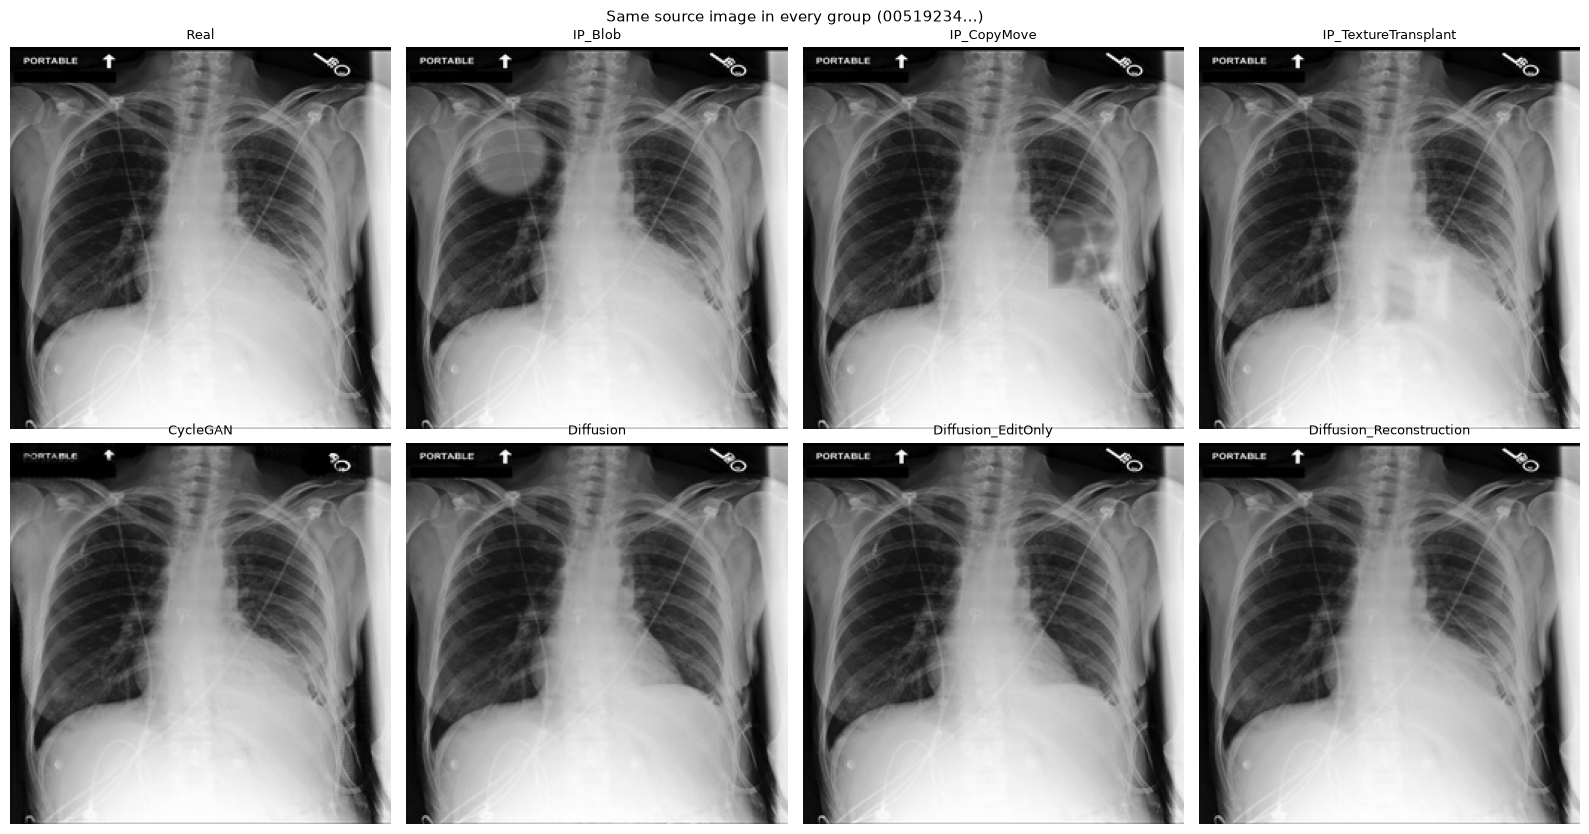

In [55]:
groups = ["Real", "IP_Blob", "IP_CopyMove", "IP_TextureTransplant",
          "CycleGAN", "Diffusion", "Diffusion_EditOnly", "Diffusion_Reconstruction"]

# One source image that exists in every group (the diffusion groups have a few fewer).
common = set.intersection(*[set(prepared.loc[prepared.frequency_group == g, "dicom_id"]) for g in groups])
dicom = sorted(common)[0]
pick = {g: prepared[(prepared.frequency_group == g) & (prepared.dicom_id == dicom)].iloc[0] for g in groups}

fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, g in zip(axes.ravel(), groups):
    ax.imshow(Image.open(pick[g].prepared_path), cmap="gray", vmin=0, vmax=255)
    ax.set_title(g, fontsize=9)
    ax.axis("off")
fig.suptitle(f"Same source image in every group ({dicom[:8]}...)", fontsize=11)
plt.tight_layout(); 
plt.show()